# Zimbabwe Healthcare Accessibility Explorer
## Notebook 3 — Exploratory Spatial Analysis
**Author: Tinashe Clifford Makandise**

### Purpose
Explore prepared facility locations, administrative reporting units and modelled population. Compare counts and population-adjusted indicators, map patterns and document interpretation limits. This notebook does not calculate nearest-facility distances or classify districts as underserved.

Run Notebooks 1 and 2 first. Save this file in the same `notebooks/` folder and use the existing `requirements-dev.txt` environment. All prepared inputs come from Notebook 2; no network access or new packages are required. Figures and tables are written to `outputs/`, with a summary in `reports/`.

The facility inventory is historical and includes government/local-authority and some not-for-profit providers, not every healthcare provider. The population grid estimates 2020 residents. Resulting ratios describe this combination of data, not current staffing, capacity, use or quality of care.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED, REPORTS = ROOT / "data/processed", ROOT / "reports"
MAPS, TABLES = ROOT / "outputs/maps", ROOT / "outputs/tables"
for folder in [MAPS, TABLES, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)
preparation = json.loads((REPORTS / "02_preparation_report.json").read_text(encoding="utf-8"))
input_names = ["facilities_prepared.geojson", "districts_prepared.geojson", "provinces_prepared.geojson", "population_cells_prepared.csv"]
input_hashes = {}
for name in input_names:
    path = PROCESSED / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Run Notebook 2 first.")
    input_hashes[name] = hashlib.sha256(path.read_bytes()).hexdigest()
    assert input_hashes[name] == preparation["output_sha256"][name], f"Prepared file changed: {name}"
facilities = gpd.read_file(PROCESSED / "facilities_prepared.geojson")
districts = gpd.read_file(PROCESSED / "districts_prepared.geojson")
provinces = gpd.read_file(PROCESSED / "provinces_prepared.geojson")
population = pd.read_csv(PROCESSED / "population_cells_prepared.csv", dtype={"adm2_pcode": "string", "adm1_pcode": "string"})
assert facilities.facility_id.is_unique and districts.adm2_pcode.is_unique and population.cell_id.is_unique
assert np.isfinite(population.population).all() and (population.population > 0).all()
assert set(facilities.adm2_pcode.dropna()).issubset(set(districts.adm2_pcode))
assert set(population.adm2_pcode.dropna()).issubset(set(districts.adm2_pcode))
np.testing.assert_allclose(population.population.sum(), preparation["population_audit"]["inside_country_population"], rtol=1e-10)
print(f"Verified {len(facilities):,} prepared facility locations, {len(districts)} districts and {len(population):,} positive in-country population cells.")
print("Facility rows without a district:", int(facilities.adm2_pcode.isna().sum()))
print("Population without a district:", float(population.loc[population.adm2_pcode.isna(), "population"].sum()))

Verified 1,201 prepared facility locations, 91 districts and 479,031 positive in-country population cells.
Facility rows without a district: 0
Population without a district: 0.0


### 1. Facility type and ownership
Report the supplied categories before aggregation. A clinic and a hospital count as one facility each in the all-facility indicator; this is not a capacity-equivalence assumption. For descriptive breakdowns only, use the source's explicit clinic and hospital labels. Unrecognised categories are kept as “Other/unclassified”, not silently discarded.

Missing-coordinate source records were excluded from mapped locations in Notebook 2 and remain in its audit tables. Thus the maps and ratios use the geolocated subset, not all 1,236 source records.

Prepared facility types:
facility_type
Clinic                          536
Rural Health Clinic             496
Rural Hospital                  108
District Hospital                47
Provincial Hospital               7
Central Hospital                  6
District/Provincial Hospital      1
Prepared ownership categories:
ownership
Local authority    643
MoH                453
FBO                104
NGO                  1
Broad groups:
facility_group
Clinic      1032
Hospital     169


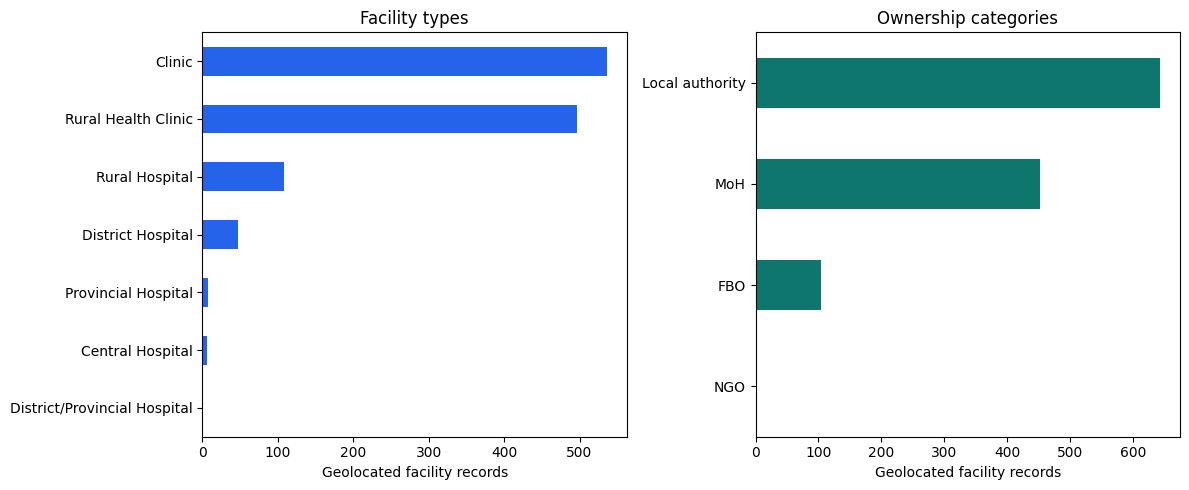

In [2]:
clinic_types = {"Clinic", "Rural Health Clinic"}
hospital_types = {"Rural Hospital", "District Hospital", "Provincial Hospital", "Central Hospital", "District/Provincial Hospital"}
facilities["facility_group"] = np.select([facilities.facility_type.isin(clinic_types), facilities.facility_type.isin(hospital_types)],
                                         ["Clinic", "Hospital"], default="Other/unclassified")
type_counts = facilities.facility_type.value_counts().rename("facilities")
ownership_counts = facilities.ownership.value_counts().rename("facilities")
print("Prepared facility types:\n" + type_counts.to_string())
print("Prepared ownership categories:\n" + ownership_counts.to_string())
print("Broad groups:\n" + facilities.facility_group.value_counts().to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
type_counts.sort_values().plot.barh(ax=axes[0], color="#2563eb")
ownership_counts.sort_values().plot.barh(ax=axes[1], color="#0f766e")
for ax in axes:
    ax.set(xlabel="Geolocated facility records", ylabel="")
axes[0].set_title("Facility types"); axes[1].set_title("Ownership categories")
plt.tight_layout()
plt.savefig(MAPS / "03_facility_type_and_ownership.png", dpi=150, bbox_inches="tight")
plt.show()

### 2. Build complete district summaries
Start from all district polygons so units with zero mapped facilities remain in the results. Join by codes, not names. Assign population using Notebook 2's native-grid-centre rule and report any unassigned records separately.

The facility-per-10,000 indicator is count divided by population times 10,000. Zero population produces an undefined ratio (NaN), not infinity or a misleading zero. District area and population density are descriptive context; area is calculated in equal-area EPSG:6933, not square degrees.

A zero count means **no facilities in the prepared inventory within that polygon**, not proof that no service exists or that residents cannot cross its border.

In [3]:
facility_counts = facilities.dropna(subset=["adm2_pcode"]).groupby("adm2_pcode").size()
population_totals = population.dropna(subset=["adm2_pcode"]).groupby("adm2_pcode").population.sum()
group_counts = pd.crosstab(facilities.adm2_pcode, facilities.facility_group)
summary = districts.copy()
summary["facility_count"] = summary.adm2_pcode.map(facility_counts).fillna(0).astype(int)
summary["population_estimate"] = summary.adm2_pcode.map(population_totals).fillna(0)
for label, column in [("Clinic", "clinic_count"), ("Hospital", "hospital_count"), ("Other/unclassified", "other_count")]:
    mapping = group_counts[label] if label in group_counts else pd.Series(dtype=int)
    summary[column] = summary.adm2_pcode.map(mapping).fillna(0).astype(int)
summary["area_km2"] = summary.to_crs(6933).area / 1e6
assert (summary.area_km2 > 0).all()
summary["population_per_km2"] = summary.population_estimate / summary.area_km2
summary["facilities_per_10000"] = np.where(summary.population_estimate > 0, summary.facility_count / summary.population_estimate * 10000, np.nan)
summary["has_population"] = summary.population_estimate.gt(0)
summary["zero_mapped_facilities"] = summary.facility_count.eq(0)
summary["district_label"] = summary.adm2_name + " (" + summary.adm2_pcode + ")"
assert summary.facility_count.sum() == facilities.adm2_pcode.notna().sum()
assert (summary[["clinic_count", "hospital_count", "other_count"]].sum(axis=1) == summary.facility_count).all()
np.testing.assert_allclose(summary.population_estimate.sum(), preparation["population_audit"]["assigned_population"], rtol=1e-10)
print(summary[["district_label", "population_estimate", "facility_count", "facilities_per_10000"]].head(10).round(3).to_string(index=False))
print("Districts with no mapped facilities:", int(summary.zero_mapped_facilities.sum()))
print("Districts with zero assigned population:", int((~summary.has_population).sum()))

           district_label  population_estimate  facility_count  facilities_per_10000
      Beitbridge (ZW1601)            83666.758              15                 1.793
Beitbridge Urban (ZW1622)            39397.599               3                 0.761
          Bikita (ZW1801)           183401.704              19                 1.036
         Bindura (ZW1201)           151734.973               7                 0.461
   Bindura Urban (ZW1221)            46109.654               6                 1.301
           Binga (ZW1501)           152035.116              19                 1.250
            Bubi (ZW1502)            75794.678               3                 0.396
          Buhera (ZW1101)           276416.484              31                 1.121
        Bulawayo (ZW1021)           645119.064              20                 0.310
        Bulilima (ZW1602)            90419.976              12                 1.327
Districts with no mapped facilities: 2
Districts with zero assign

### 3. Province and national comparisons
Aggregate district counts/population by province, then calculate the ratio from those totals. Do not average district ratios without weights: a small district and a large district would otherwise have equal influence.

Facility share minus population share is a descriptive distribution comparison. It is not a capacity-adjusted allocation target, a demand estimate or an accessibility score.

In [4]:
province_table = summary.groupby(["adm1_pcode", "adm1_name"], as_index=False).agg(
    population_estimate=("population_estimate", "sum"), facility_count=("facility_count", "sum"),
    clinic_count=("clinic_count", "sum"), hospital_count=("hospital_count", "sum"),
    area_km2=("area_km2", "sum"))
province_table["facilities_per_10000"] = np.where(province_table.population_estimate > 0, province_table.facility_count / province_table.population_estimate * 10000, np.nan)
province_table["facility_share_percent"] = province_table.facility_count / province_table.facility_count.sum() * 100
province_table["population_share_percent"] = province_table.population_estimate / province_table.population_estimate.sum() * 100
province_table["facility_minus_population_share_pp"] = province_table.facility_share_percent - province_table.population_share_percent
national_facilities = int(summary.facility_count.sum())
national_population = float(summary.population_estimate.sum())
national_ratio = national_facilities / national_population * 10000
print(province_table[["adm1_name", "population_estimate", "facility_count", "facilities_per_10000"]].sort_values("facilities_per_10000").round(3).to_string(index=False))
print(f"Assigned national denominator: {national_population:,.0f} estimated residents.")
print(f"Mapped facilities per 10,000 estimated residents: {national_ratio:.3f}")
np.testing.assert_allclose(province_table.population_estimate.sum(), national_population, rtol=1e-10)
assert province_table.facility_count.sum() == national_facilities

          adm1_name  population_estimate  facility_count  facilities_per_10000
             Harare          2376243.964              27                 0.114
           Bulawayo           645119.064              20                 0.310
   Mashonaland West          1810507.189             137                 0.757
           Masvingo          1686364.256             151                 0.895
           Midlands          1802653.773             163                 0.904
Mashonaland Central          1335539.572             122                 0.913
   Mashonaland East          1671014.919             169                 1.011
 Matabeleland North           826566.568              88                 1.065
         Manicaland          1978604.361             221                 1.117
 Matabeleland South           719230.469             103                 1.432
Assigned national denominator: 14,851,844 estimated residents.
Mapped facilities per 10,000 estimated residents: 0.809


### 4. Compare three district choropleths
Compare mapped facility counts, population estimates and facilities per 10,000 residents. Each map has its own colour scale and must be interpreted with its legend. Large polygons dominate visual area but do not necessarily contain more residents. These maps are exploratory; no geographic access or travel-time classification is inferred.

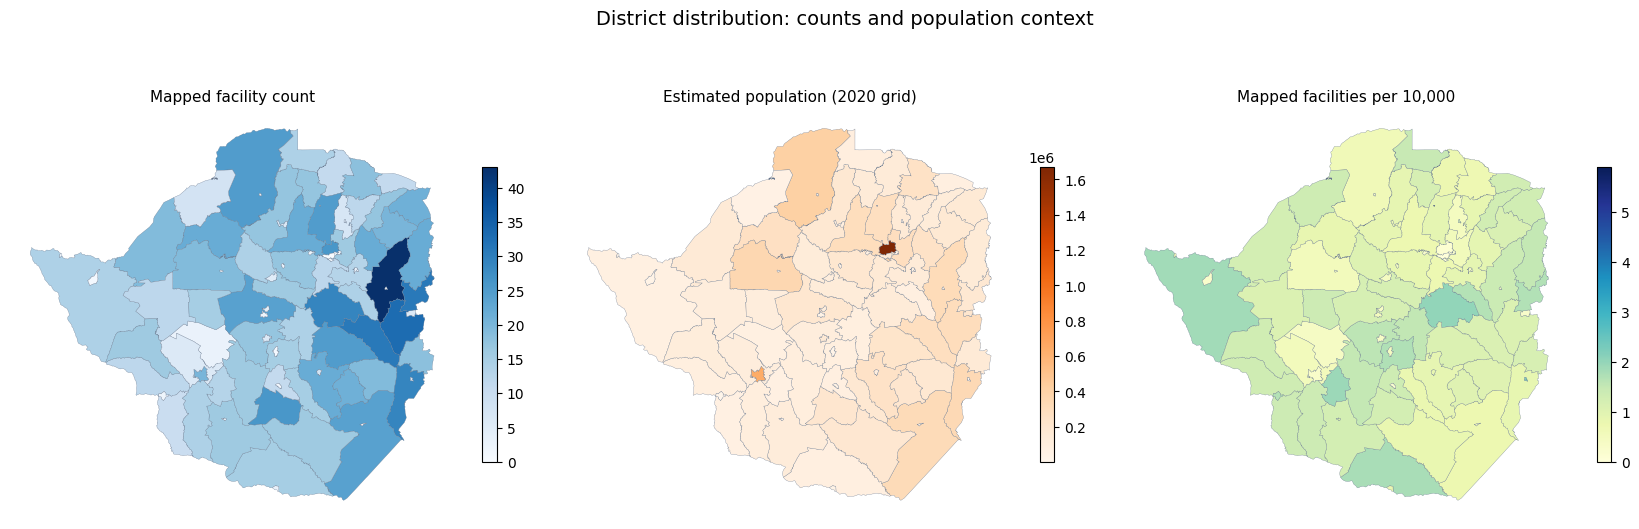

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
map_specs = [("facility_count", "Mapped facility count", "Blues"),
             ("population_estimate", "Estimated population (2020 grid)", "Oranges"),
             ("facilities_per_10000", "Mapped facilities per 10,000", "YlGnBu")]
for ax, (column, title, cmap) in zip(axes, map_specs):
    summary.plot(column=column, cmap=cmap, ax=ax, legend=True, linewidth=.2, edgecolor="#64748b",
                 missing_kwds={"color": "lightgray", "label": "Undefined"},
                 legend_kwds={"shrink": .55})
    ax.set_title(title, fontsize=11)
    ax.set_axis_off()
plt.suptitle("District distribution: counts and population context", fontsize=14)
plt.tight_layout()
plt.savefig(MAPS / "03_district_counts_population_and_ratio.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Compare ordering by counts and by population-adjusted ratios
Display the ten districts with the largest mapped facility counts and the ten with the lowest population-adjusted ratios. They need not be the same districts.

“Lowest ratio” does not mean “worst access”. Facility capacity, missing providers, cross-border use, settlement patterns and source-year differences can all change interpretation. These are descriptive tables to guide the next analysis, not a facility-placement recommendation.

Lowest-ratio districts (descriptive, not an access ranking):
           district_label  facility_count  population_estimate  facilities_per_10000
         Epworth (ZW1923)               0           181337.033                 0.000
    Harare Rural (ZW1924)               0           154691.521                 0.000
     Chitungwiza (ZW1922)               1           369616.867                 0.027
          Harare (ZW1921)              26          1670598.543                 0.156
Zvishavane Urban (ZW1725)               1            50965.875                 0.196
          Norton (ZW1425)               2            75445.120                 0.265
    Hwange Urban (ZW1521)               1            37451.510                 0.267
    Mutare Urban (ZW1121)               6           214199.767                 0.280
            Ruwa (ZW1326)               2            70913.409                 0.282
        Bulawayo (ZW1021)              20           645119.064                 0.310


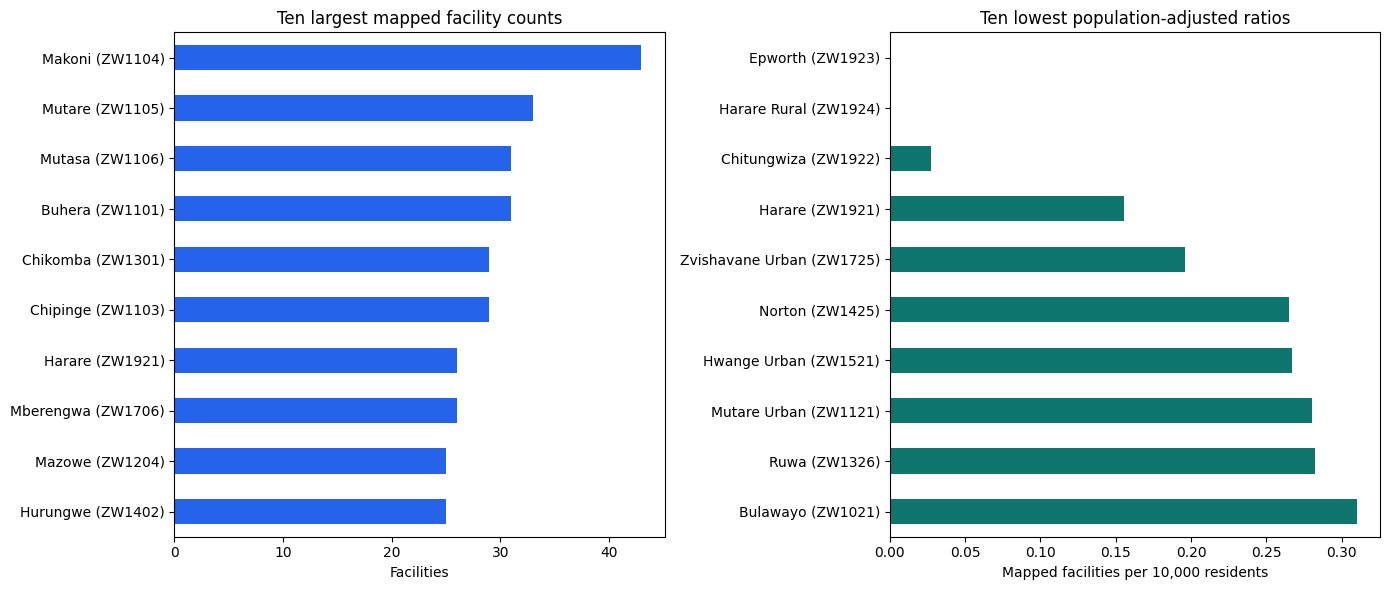

In [6]:
highest_counts = summary.sort_values(["facility_count", "adm2_pcode"], ascending=[False, True]).head(10)
lowest_ratios = summary.loc[summary.has_population].sort_values(["facilities_per_10000", "adm2_pcode"]).head(10)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
highest_counts.sort_values("facility_count").plot.barh(x="district_label", y="facility_count", ax=axes[0], legend=False, color="#2563eb")
lowest_ratios.sort_values("facilities_per_10000", ascending=False).plot.barh(x="district_label", y="facilities_per_10000", ax=axes[1], legend=False, color="#0f766e")
axes[0].set(title="Ten largest mapped facility counts", xlabel="Facilities", ylabel="")
axes[1].set(title="Ten lowest population-adjusted ratios", xlabel="Mapped facilities per 10,000 residents", ylabel="")
plt.tight_layout()
plt.savefig(MAPS / "03_district_count_and_ratio_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Lowest-ratio districts (descriptive, not an access ranking):")
print(lowest_ratios[["district_label", "facility_count", "population_estimate", "facilities_per_10000"]].round(3).to_string(index=False))

### 6. Examine population and facility counts together
Plot district population against mapped facility count. A logarithmic population axis makes districts of different sizes visible. The reference line shows what the national inventory ratio would imply at each population size; it is not an official service standard, a regression fit or a planning target.

Ratios can be especially sensitive in small urban reporting units. A district's residents may use services across its boundary. Nearest-facility distances in Notebook 4 will therefore search all prepared in-country facilities, not just those assigned to the same district.

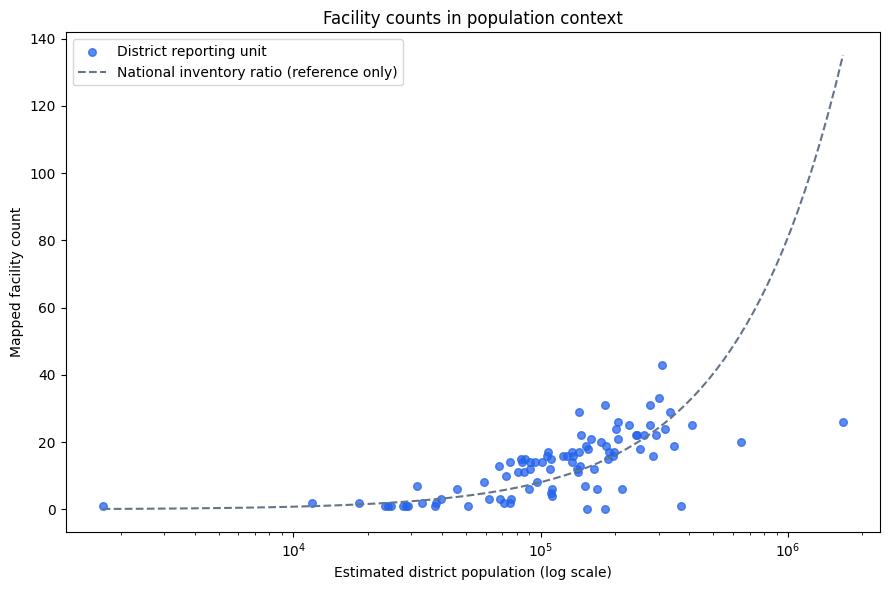

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
positive = summary[summary.population_estimate > 0]
ax.scatter(positive.population_estimate, positive.facility_count, s=30, alpha=.75, color="#2563eb", label="District reporting unit")
reference_x = np.geomspace(positive.population_estimate.min(), positive.population_estimate.max(), 100)
ax.plot(reference_x, reference_x * national_ratio / 10000, linestyle="--", color="#64748b", label="National inventory ratio (reference only)")
ax.set_xscale("log")
ax.set(xlabel="Estimated district population (log scale)", ylabel="Mapped facility count", title="Facility counts in population context")
ax.legend()
plt.tight_layout()
plt.savefig(MAPS / "03_population_vs_facility_count.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Export descriptive results and data-derived findings
Export district and province summaries, category counts and a GeoJSON layer with descriptive indicators. No accessibility distance has been calculated yet. Preserve the source caveats when displaying these outputs in the future app.

Prepared input hashes are checked again to confirm this notebook did not alter upstream data. District counts reconcile to assigned facilities and population; missing-coordinate facilities remain excluded from these mapped ratios.

In [8]:
table_columns = [c for c in summary.columns if c != "geometry"]
summary[table_columns].to_csv(TABLES / "03_district_descriptive_summary.csv", index=False)
province_table.to_csv(TABLES / "03_province_descriptive_summary.csv", index=False)
type_counts.to_csv(TABLES / "03_facility_type_counts.csv", index_label="facility_type")
ownership_counts.to_csv(TABLES / "03_ownership_counts.csv", index_label="ownership")
summary.to_file(PROCESSED / "districts_descriptive_indicators.geojson", driver="GeoJSON")
minimum = lowest_ratios.iloc[0]
maximum = highest_counts.iloc[0]
findings = [
    f"Prepared mapped facilities: {national_facilities:,}; district reporting units: {len(summary)}.",
    f"Assigned 2020-grid population denominator: {national_population:,.0f} estimated residents.",
    f"National mapped-facility ratio: {national_ratio:.3f} per 10,000 estimated residents.",
    f"Largest count: {maximum['district_label']} with {maximum['facility_count']} mapped facilities.",
    f"Lowest population-adjusted ratio: {minimum['district_label']} at {minimum['facilities_per_10000']:.3f} per 10,000; not a measured access ranking.",
    f"Districts with zero mapped facilities: {int(summary.zero_mapped_facilities.sum())}.",
    "35 missing-coordinate source records were retained in the upstream audit but excluded from mapped analyses.",
    "Two source-province disagreements remain flagged; this analysis uses the spatial district assignments.",
    "Historical facilities and 2020 modelled population form a mixed-period exploratory analysis, not current healthcare coverage.",
    "Facility counts do not measure capacity, affordability, travel time or quality. Nearest-facility analysis follows in Notebook 4.",
]
(REPORTS / "03_exploratory_findings.md").write_text("# Exploratory findings\n\n" + "\n".join("- " + item for item in findings) + "\n", encoding="utf-8")
record = {"author": "Tinashe Clifford Makandise", "mapped_facilities": national_facilities,
          "districts": len(summary), "population_denominator": national_population,
          "facilities_per_10000": national_ratio,
          "unassigned_facilities": int(facilities.adm2_pcode.isna().sum()),
          "unassigned_population": float(population.loc[population.adm2_pcode.isna(), "population"].sum()),
          "input_sha256": input_hashes, "analysis": "descriptive only; no accessibility distances",
          "output_files": ["outputs/tables/03_district_descriptive_summary.csv", "outputs/tables/03_province_descriptive_summary.csv", "data/processed/districts_descriptive_indicators.geojson"]}
(REPORTS / "03_exploratory_report.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
for name, digest in input_hashes.items():
    assert hashlib.sha256((PROCESSED / name).read_bytes()).hexdigest() == digest
print("\n".join(findings))
print("Exports complete; upstream prepared files unchanged.")

Prepared mapped facilities: 1,201; district reporting units: 91.
Assigned 2020-grid population denominator: 14,851,844 estimated residents.
National mapped-facility ratio: 0.809 per 10,000 estimated residents.
Largest count: Makoni (ZW1104) with 43 mapped facilities.
Lowest population-adjusted ratio: Epworth (ZW1923) at 0.000 per 10,000; not a measured access ranking.
Districts with zero mapped facilities: 2.
35 missing-coordinate source records were retained in the upstream audit but excluded from mapped analyses.
Two source-province disagreements remain flagged; this analysis uses the spatial district assignments.
Historical facilities and 2020 modelled population form a mixed-period exploratory analysis, not current healthcare coverage.
Facility counts do not measure capacity, affordability, travel time or quality. Nearest-facility analysis follows in Notebook 4.
Exports complete; upstream prepared files unchanged.


### Review and next step
1. Why can a district have many facilities but a low per-population ratio?
2. Why must the national ratio be calculated from total counts and population?
3. Why do province/district boundaries not represent barriers to healthcare use?
4. What do the 35 missing-coordinate records imply for completeness?
5. Why do descriptive facility counts not establish population accessibility?

**Next: Notebook 4 — Population Accessibility Analysis.** Calculate nearest-facility distances from population-cell centres, retain population weighting, compare illustrative thresholds and summarise the results by district. No threshold is an official healthcare standard, and no result will establish service quality or actual travel time.